In [1]:
# Checked (final)

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
from statsmodels import robust
import matplotlib.pyplot as plt
from metricsCalculation import DataPreparationUtils as utils

In [3]:
listOf1ServerLogs = {
    '../data/1_server/5_clients': 5,
    '../data/1_server/10_clients': 10,
    '../data/1_server/15_clients': 15,
    '../data/1_server/20_clients': 20,
    '../data/1_server/25_clients': 25,
    '../data/1_server/30_clients': 30,
}

listOf3ServerLogs = {
    '../data/3_server/5_clients': 5,
    '../data/3_server/10_clients': 10,
    '../data/3_server/15_clients': 15,
    '../data/3_server/20_clients': 20,
    '../data/3_server/25_clients': 25,
    '../data/3_server/30_clients': 30,
}

listOf5ServerLogs = {
    '../data/5_server/5_clients': 5,
    '../data/5_server/10_clients': 10,
    '../data/5_server/15_clients': 15,
    '../data/5_server/20_clients': 20,
    '../data/5_server/25_clients': 25,
    '../data/5_server/30_clients': 30,
}

In [4]:
dfSLAMM1Server = pd.DataFrame(columns=['Number of Mobile Sensing Clients', 'S_LAMM (Median)', 'MAD'])
dfSLAMM1ServerBoxPlot = pd.DataFrame(columns=['Server', 'Clients', 'S_LAMM'])

for (logPath, clientNumber) in listOf1ServerLogs.items():
    dfLog = utils.readInServerLogsForScenario(logPath)[0]

    for i, row in dfLog.iterrows():
        dfSLAMM1ServerBoxPlot.loc[len(dfSLAMM1ServerBoxPlot)] = [1, clientNumber, int(row['time to to generate the LAMM and the message containing the LAMM with global density data in milliseconds'])]

    dfLogDescribe = dfLog.describe()
    print("Metrics for Scenario ({} Server / {} Clients): ".format(1, clientNumber))
    print(dfLogDescribe['time to to generate the LAMM and the message containing the LAMM with global density data in milliseconds'])
    print("--------------------------------------------------------------------------")
    median = dfLogDescribe.iat[5,0]

    dfLogMAD = robust.mad(dfLog['time to to generate the LAMM and the message containing the LAMM with global density data in milliseconds'])

    dfSLAMM1Server.loc[len(dfSLAMM1Server)] = [clientNumber, median, dfLogMAD]

dfSLAMM3Server = pd.DataFrame(columns=['Number of Mobile Sensing Clients', 'S_LAMM (Median)', 'MAD'])
dfSLAMM3ServerBoxPlot = pd.DataFrame(columns=['Server', 'Clients', 'S_LAMM'])

for (logPath, clientNumber) in listOf3ServerLogs.items():
    dfLog = utils.readInServerLogsForScenario(logPath)[0]

    for i, row in dfLog.iterrows():
        dfSLAMM3ServerBoxPlot.loc[len(dfSLAMM3ServerBoxPlot)] = [3, clientNumber, int(row['time to to generate the LAMM and the message containing the LAMM with global density data in milliseconds'])]

    dfLogDescribe = dfLog.describe()
    print("Metrics for Scenario ({} Server / {} Clients): ".format(3, clientNumber))
    print(dfLogDescribe['time to to generate the LAMM and the message containing the LAMM with global density data in milliseconds'])
    print("--------------------------------------------------------------------------")
    median = dfLogDescribe.iat[5,0]

    dfLogMAD = robust.mad(dfLog['time to to generate the LAMM and the message containing the LAMM with global density data in milliseconds'])

    dfSLAMM3Server.loc[len(dfSLAMM3Server)] = [clientNumber, median, dfLogMAD]

dfSLAMM5Server = pd.DataFrame(columns=['Number of Mobile Sensing Clients', 'S_LAMM (Median)', 'MAD'])
dfSLAMM5ServerBoxPlot = pd.DataFrame(columns=['Server', 'Clients', 'S_LAMM'])

for (logPath, clientNumber) in listOf5ServerLogs.items():
    dfLog = utils.readInServerLogsForScenario(logPath)[0]

    for i, row in dfLog.iterrows():
        dfSLAMM5ServerBoxPlot.loc[len(dfSLAMM5ServerBoxPlot)] = [5, clientNumber, int(row['time to to generate the LAMM and the message containing the LAMM with global density data in milliseconds'])]

    dfLogDescribe = dfLog.describe()
    print("Metrics for Scenario ({} Server / {} Clients): ".format(5, clientNumber))
    print(dfLogDescribe['time to to generate the LAMM and the message containing the LAMM with global density data in milliseconds'])
    print("--------------------------------------------------------------------------")
    median = dfLogDescribe.iat[5,0]

    dfLogMAD = robust.mad(dfLog['time to to generate the LAMM and the message containing the LAMM with global density data in milliseconds'])

    dfSLAMM5Server.loc[len(dfSLAMM5Server)] = [clientNumber, median, dfLogMAD]

Metrics for Scenario (1 Server / 5 Clients): 
count    125.000000
mean      19.336000
std        4.621032
min       16.000000
25%       18.000000
50%       18.000000
75%       19.000000
max       59.000000
Name: time to to generate the LAMM and the message containing the LAMM with global density data in milliseconds, dtype: float64
--------------------------------------------------------------------------
Metrics for Scenario (1 Server / 10 Clients): 
count    81.000000
mean     22.209877
std       4.395213
min      18.000000
25%      20.000000
50%      21.000000
75%      23.000000
max      56.000000
Name: time to to generate the LAMM and the message containing the LAMM with global density data in milliseconds, dtype: float64
--------------------------------------------------------------------------
Metrics for Scenario (1 Server / 15 Clients): 
count    80.000000
mean     25.462500
std       6.384205
min      20.000000
25%      23.000000
50%      24.000000
75%      25.000000
max      

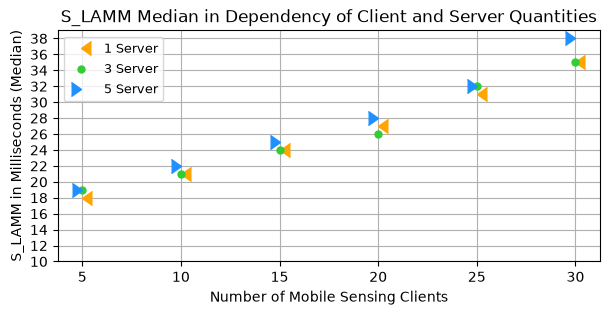

In [5]:
figure = plt.figure()

plt.plot(dfSLAMM1Server['Number of Mobile Sensing Clients'], dfSLAMM1Server['S_LAMM (Median)'],linestyle='', marker=4, label='1 Server', color='orange', markersize=10)
plt.plot(dfSLAMM3Server['Number of Mobile Sensing Clients'], dfSLAMM3Server['S_LAMM (Median)'],linestyle='', marker='.', label='3 Server', color='limegreen', markersize=10)
plt.plot(dfSLAMM5Server['Number of Mobile Sensing Clients'], dfSLAMM5Server['S_LAMM (Median)'],linestyle='', marker=5, label='5 Server', color='dodgerblue', markersize=10)

plt.title("S_LAMM Median in Dependency of Client and Server Quantities")
plt.xlabel("Number of Mobile Sensing Clients")
plt.ylabel("S_LAMM in Milliseconds (Median)")

plt.yticks(np.arange(10, 40, 2))

'''
for i, row in dfSLAMM1Server.iterrows():
    # plt.text(x=row['Number of Mobile Sensing Clients']+0.3, y=row['S_LAMM (Median)']-0.25, s=round(row['MAD'], 2), color='orange', horizontalalignment = 'left')
    plt.text(x=row['Number of Mobile Sensing Clients']+0.3, y=row['S_LAMM (Median)']-0.25, s=row['S_LAMM (Median)'], color='orange', horizontalalignment = 'left')
for i, row in dfSLAMM3Server.iterrows():
    # plt.text(x=row['Number of Mobile Sensing Clients']+0.2, y=row['S_LAMM (Median)']-0.75, s=round(row['MAD'], 2), color='red')
    plt.text(x=row['Number of Mobile Sensing Clients']+0.2, y=row['S_LAMM (Median)']-0.75, s=row['S_LAMM (Median)'], color='red')
for i, row in dfSLAMM5Server.iterrows():
    # plt.text(x=row['Number of Mobile Sensing Clients']-0.3, y=row['S_LAMM (Median)']-0.25, s=round(row['MAD'], 2), color='dodgerblue', horizontalalignment = 'right')
    plt.text(x=row['Number of Mobile Sensing Clients']-0.3, y=row['S_LAMM (Median)']-0.25, s=row['S_LAMM (Median)'], color='dodgerblue', horizontalalignment = 'right')
'''

plt.grid()
plt.legend(fontsize=9)

figure.set_figwidth(7)
figure.set_figheight(3)

plt.show()

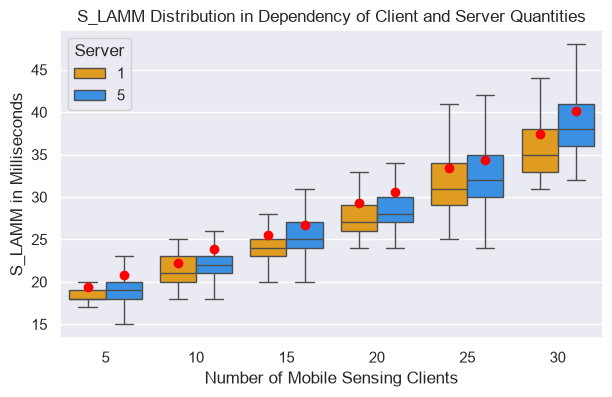

In [10]:
sns.set_theme(rc={"figure.figsize": (7,4)})

sns.boxplot(data=pd.concat([dfSLAMM1ServerBoxPlot, dfSLAMM5ServerBoxPlot]), showfliers=False, showmeans=True, meanprops={'marker': 'o', 'markerfacecolor': 'red', 'markeredgecolor':'red'}, hue="Server", x='Clients', y='S_LAMM', palette=['orange', 'dodgerblue']).set(title="S_LAMM Distribution in Dependency of Client and Server Quantities", xlabel="Number of Mobile Sensing Clients", ylabel="S_LAMM in Milliseconds")

#plt.grid()
plt.show()

In [7]:
dfSLAMM1Server

,Number of Mobile Sensing Clients,S_LAMM (Median),MAD
0,5.0,18.0,0.000000
1,10.0,21.0,1.482602
2,15.0,24.0,1.482602
3,20.0,27.0,2.223903
4,25.0,31.0,2.965204
5,30.0,35.0,2.965204


In [8]:
dfSLAMM5Server

,Number of Mobile Sensing Clients,S_LAMM (Median),MAD
0,5.0,19.0,1.482602
1,10.0,22.0,1.482602
2,15.0,25.0,1.482602
3,20.0,28.0,2.965204
4,25.0,32.0,2.965204
5,30.0,38.0,2.965204
